# Aviation Accidents Analysis

You are part of a consulting firm that is tasked to do an analysis of commercial and passenger jet airline safety. The client (an airline/airplane insurer) is interested in knowing what types of aircraft (makes/models) exhibit low rates of total destruction and low likelihood of fatal or serious passenger injuries in the event of an accident. They are also interested in any general variables/conditions that might be at play. Your analysis will be based off of aviation accident data accumulated from the years 1948-2023. 

Our client is only interested in airplane makes/models that are professional builds and could potentially still be active. Assume a max lifetime of 40 years for a make/model retirement and make sure to filter your data accordingly (i.e. from 1983 onwards). They would also like separate recommendations for small aircraft vs. larger passenger models. **In addition, make sure that claims that you make are statistically robust and that you have enough samples when making comparisons between groups.**


In this summative assessment you will demonstrate your ability to:
- Use Pandas to load, inspect, and clean the dataset appropriately. 
- Transform relevant columns to create measures that address the problem at hand.
- **conduct EDA: visualization and statistical measures to understand the structure of the data**
- **recommend a set of manufacturers to consider as well as specific airplanes conforming to the client's request**
- **discuss the relationship between serious injuries/airplane damage incurred and at least *two* factors at play in the incident. You must provide supporting evidence (visuals, summary statistics, tables) for each claim you make.**

In [1]:
# loading relevant packages
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Exploratory Data Analysis  
- Load in the cleaned data

In [6]:
#loading the cleaned data
df = pd.read_csv('Aviation_Accidents_Cleaned.csv')

# Display the data
print(df.shape)
print(df.columns.tolist())
df.head()

(17879, 32)
['Event.Id', 'Investigation.Type', 'Accident.Number', 'Event.Date', 'Location', 'Country', 'Latitude', 'Longitude', 'Airport.Code', 'Airport.Name', 'Injury.Severity', 'Aircraft.damage', 'Aircraft.Category', 'Registration.Number', 'Make', 'Model', 'Amateur.Built', 'Number.of.Engines', 'Engine.Type', 'FAR.Description', 'Purpose.of.flight', 'Air.carrier', 'Total.Fatal.Injuries', 'Total.Serious.Injuries', 'Total.Minor.Injuries', 'Total.Uninjured', 'Weather.Condition', 'Broad.phase.of.flight', 'Report.Status', 'Publication.Date', 'Aircraft.Destroyed', 'Aircraft.Type']


C:\Users\USER\AppData\Local\Temp\ipykernel_10364\4224183789.py:2: DtypeWarning: Columns (0: Event.Id, 1: Broad.phase.of.flight) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv('Aviation_Accidents_Cleaned.csv')


,Event.Id,Investigation.Type,Accident.Number,Event.Date,Location,Country,Latitude,Longitude,Airport.Code,Airport.Name,...,Total.Fatal.Injuries,Total.Serious.Injuries,Total.Minor.Injuries,Total.Uninjured,Weather.Condition,Broad.phase.of.flight,Report.Status,Publication.Date,Aircraft.Destroyed,Aircraft.Type
0,20001214X42478,Incident,LAX83IA149A,1983-03-18,"LOS ANGELES, CA",United States,NaN,NaN,LAX,LOS ANGELES INTL,...,NaN,NaN,NaN,588.0,VMC,Taxi,Probable Cause,04-12-2014,True,BOEING - 747
1,20001214X42331,Accident,ATL83FA140,1983-03-20,"CROSSVILLE, TN",United States,NaN,NaN,NaN,NaN,...,1.0,1.0,NaN,NaN,IMC,Cruise,Probable Cause,02-05-2011,True,PIPER - PA-28-140
2,20001214X42672,Accident,FTW83LA177,1983-04-02,"MCKINNEY, TX",United States,NaN,NaN,TX05,AERO COUNTRY,...,1.0,NaN,NaN,4.0,VMC,Standing,Probable Cause,17-10-2016,False,DE HAVILLAND - DHC-6
3,20001214X45013,Incident,CHI84IA041,1983-11-08,"CHICAGO, IL",United States,NaN,NaN,ORD,O'HARE,...,NaN,NaN,NaN,100.0,VMC,Taxi,Probable Cause,11-06-2018,True,BOEING - 727-200
4,20001214X45188,Accident,NYC84LA028,1983-11-13,"MARTHA'S VINEYARD, MA",United States,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,1.0,VMC,Climb,Probable Cause,05-05-2011,True,BEECH - C35


## Explore safety metrics across models/makes
- Remember that the client is interested in separate recommendations for smaller airplanes and larger airplanes. Choose a passenger threshold of 20 and separate the plane types. 

In [12]:
df['Event.Date'] = pd.to_datetime(df['Event.Date'])
df_filtered = df[(df['Event.Date'].dt.year >= 1983) & (df['Amateur.Built'] == 'No')]
print(df_filtered.shape)

(17879, 32)


In [13]:
# 1. Create Total Passengers column
df_filtered['Total_Passengers'] = (
    df_filtered['Total.Fatal.Injuries'] + 
    df_filtered['Total.Serious.Injuries'] + 
    df_filtered['Total.Minor.Injuries'] + 
    df_filtered['Total.Uninjured']
)

# 2. Separate plane types using threshold = 20
df_filtered['Plane_Type'] = df_filtered['Total_Passengers'].apply(
    lambda x: 'Small' if x < 20 else 'Large'
)

# 3. Quick check
df_filtered[['Total_Passengers', 'Plane_Type']].head(10)
df_filtered['Plane_Type'].value_counts()

Plane_Type
Small    14479
Large     3400
Name: count, dtype: int64

#### Analyzing Makes

Explore the human injury risk profile for small and larger Makes:
- choose the 15 makes for each group possessing the lowest mean fatal/seriously injured fraction
- plot the mean fatal/seriously injured fraction for each of these subgroups side-by-side

In [14]:
# Injury fraction = (Fatal + Serious) / Total Passengers
df_filtered['Injury_Fraction'] = (
    df_filtered['Total.Fatal.Injuries'] + df_filtered['Total.Serious.Injuries']
) / df_filtered['Total_Passengers']

# Handle divide by 0 cases
df_filtered['Injury_Fraction'] = df_filtered['Injury_Fraction'].fillna(0)

In [15]:
safety_metrics = df_filtered.groupby(['Plane_Type', 'Make'])['Injury_Fraction'].mean().reset_index()
safety_metrics.head()

,Plane_Type,Make,Injury_Fraction
0,Large,AERO COMMANDER,0.000000
1,Large,AERONCA,0.000000
2,Large,AIR TRACTOR,0.000000
3,Large,AIR TRACTOR INC,0.000000
4,Large,AIRBUS,0.075846


In [16]:
# Top 15 safest Small planes
top15_small = safety_metrics[safety_metrics['Plane_Type'] == 'Small'].nsmallest(15, 'Injury_Fraction')

# Top 15 safest Large planes  
top15_large = safety_metrics[safety_metrics['Plane_Type'] == 'Large'].nsmallest(15, 'Injury_Fraction')

top15_small
top15_large

,Plane_Type,Make,Injury_Fraction
0,Large,AERO COMMANDER,0.0
1,Large,AERONCA,0.0
2,Large,AIR TRACTOR,0.0
3,Large,AIR TRACTOR INC,0.0
5,Large,AMERICAN CHAMPION AIRCRAFT,0.0
6,Large,AVIAT,0.0
7,Large,AYRES,0.0
9,Large,BELLANCA,0.0
13,Large,CESSNA,0.0
14,Large,CHAMPION,0.0


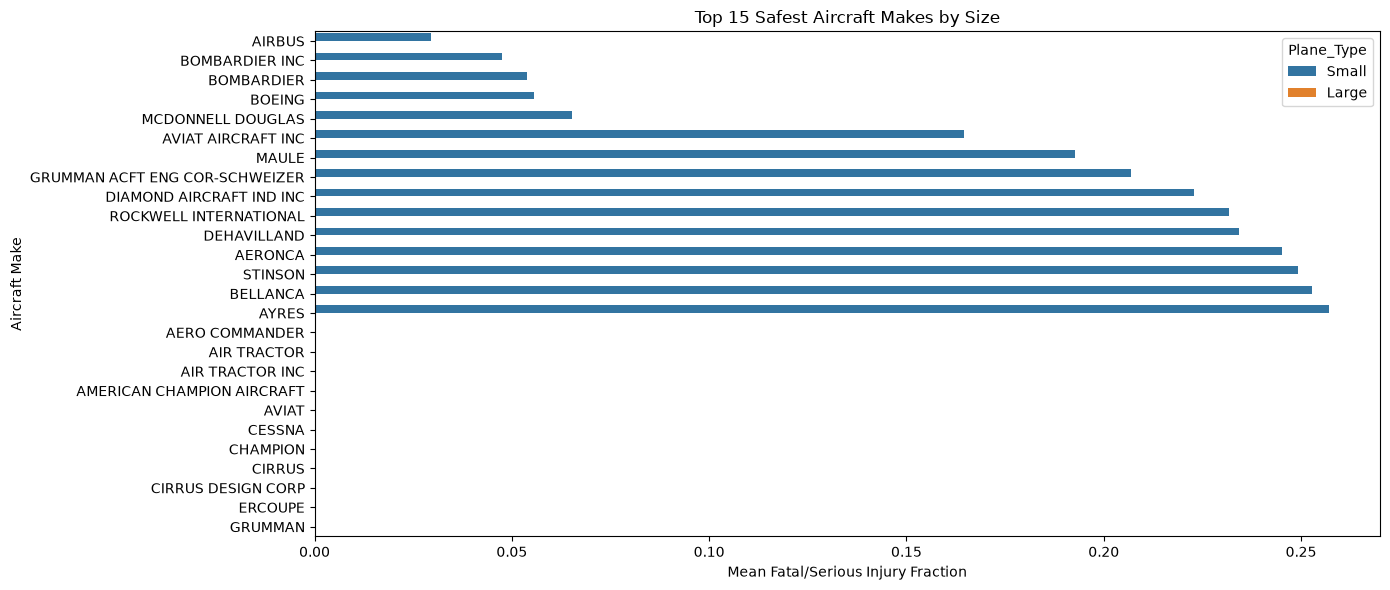

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns

top15_combined = pd.concat([top15_small, top15_large])

plt.figure(figsize=(14, 6))
sns.barplot(data=top15_combined, x='Injury_Fraction', y='Make', hue='Plane_Type')
plt.title('Top 15 Safest Aircraft Makes by Size')
plt.xlabel('Mean Fatal/Serious Injury Fraction')
plt.ylabel('Aircraft Make')
plt.tight_layout()
plt.show()

**Distribution of injury rates: small makes**

Use a violinplot to look at the distribution of the fraction of passengers serious/fatally injured for small airplane makes. Just display makes with the ten lowest mean serious/fatal injury rates.

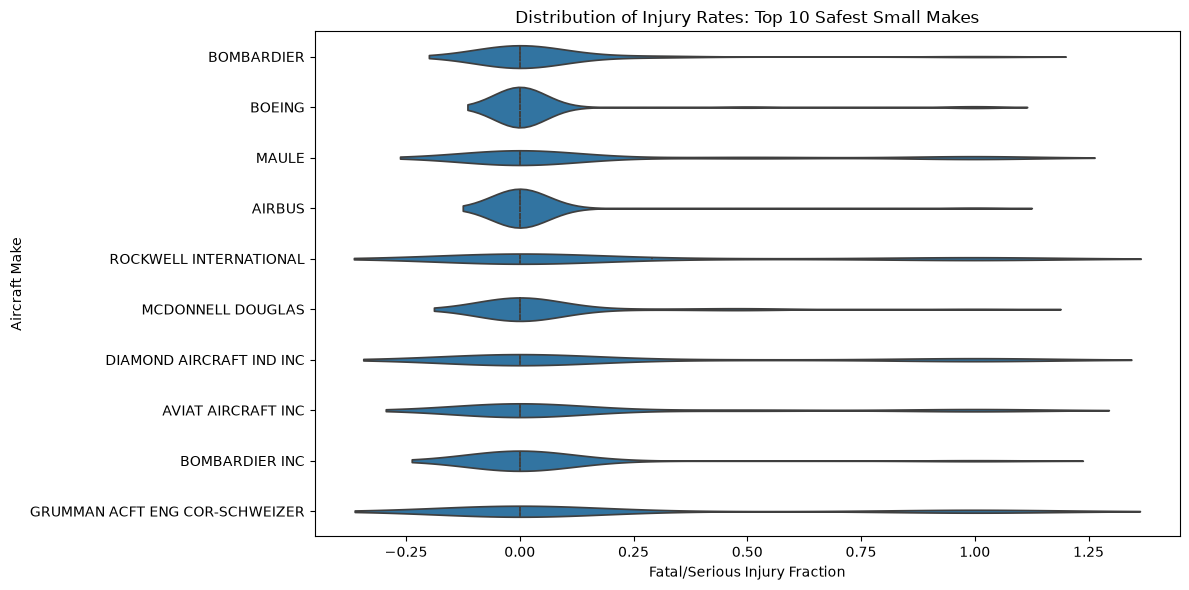

In [18]:
# Get top 10 safest small makes
top10_small = safety_metrics[safety_metrics['Plane_Type'] == 'Small'].nsmallest(10, 'Injury_Fraction')
top10_small_makes = top10_small['Make'].tolist()

# Filter original data to just those 10 makes and only Small planes
df_small_top10 = df_filtered[
    (df_filtered['Plane_Type'] == 'Small') & 
    (df_filtered['Make'].isin(top10_small_makes))
]

plt.figure(figsize=(12, 6))
sns.violinplot(data=df_small_top10, x='Injury_Fraction', y='Make', inner='quartile')
plt.title('Distribution of Injury Rates: Top 10 Safest Small Makes')
plt.xlabel('Fatal/Serious Injury Fraction')
plt.ylabel('Aircraft Make')
plt.tight_layout()
plt.show()

**Distribution of injury rates: large makes**

Use a stripplot to look at the distribution of the fraction of passengers serious/fatally injured for large airplane makes. Just display makes with the ten lowest mean serious/fatal injury rates.

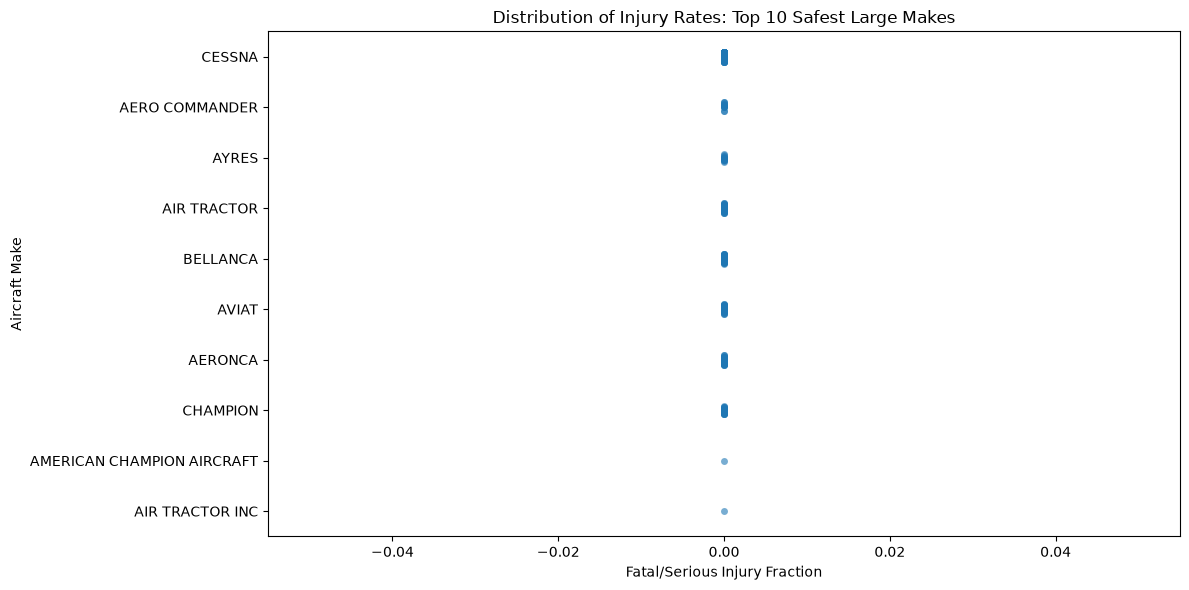

In [19]:
# Get top 10 safest large makes
top10_large = safety_metrics[safety_metrics['Plane_Type'] == 'Large'].nsmallest(10, 'Injury_Fraction')
top10_large_makes = top10_large['Make'].tolist()

# Filter original data to just those 10 makes and only Large planes
df_large_top10 = df_filtered[
    (df_filtered['Plane_Type'] == 'Large') & 
    (df_filtered['Make'].isin(top10_large_makes))
]

plt.figure(figsize=(12, 6))
sns.stripplot(data=df_large_top10, x='Injury_Fraction', y='Make', jitter=True, alpha=0.6)
plt.title('Distribution of Injury Rates: Top 10 Safest Large Makes')
plt.xlabel('Fatal/Serious Injury Fraction')
plt.ylabel('Aircraft Make')
plt.tight_layout()
plt.show()

**Evaluate the rate of aircraft destruction for both small and large aircraft by Make.** 

Sort your results and keep the lowest 15.

In [20]:
# Convert Aircraft.Destroyed to 1/0 so we can take mean
df_filtered['Destroyed_Flag'] = df_filtered['Aircraft.Destroyed'].apply(lambda x: 1 if x == 'Yes' else 0)

# Calculate destruction rate by Make + Plane_Type
destruction_rate = df_filtered.groupby(['Plane_Type', 'Make'])['Destroyed_Flag'].mean().reset_index()
destruction_rate = destruction_rate.rename(columns={'Destroyed_Flag': 'Destruction_Rate'})

destruction_rate.head()

,Plane_Type,Make,Destruction_Rate
0,Large,AERO COMMANDER,0.0
1,Large,AERONCA,0.0
2,Large,AIR TRACTOR,0.0
3,Large,AIR TRACTOR INC,0.0
4,Large,AIRBUS,0.0


In [21]:
# Lowest 15 for Small
lowest15_small_destroy = destruction_rate[destruction_rate['Plane_Type'] == 'Small'].nsmallest(15, 'Destruction_Rate')

# Lowest 15 for Large
lowest15_large_destroy = destruction_rate[destruction_rate['Plane_Type'] == 'Large'].nsmallest(15, 'Destruction_Rate')

lowest15_small_destroy
lowest15_large_destroy

,Plane_Type,Make,Destruction_Rate
0,Large,AERO COMMANDER,0.0
1,Large,AERONCA,0.0
2,Large,AIR TRACTOR,0.0
3,Large,AIR TRACTOR INC,0.0
4,Large,AIRBUS,0.0
5,Large,AMERICAN CHAMPION AIRCRAFT,0.0
6,Large,AVIAT,0.0
7,Large,AYRES,0.0
8,Large,BEECH,0.0
9,Large,BELLANCA,0.0


#### Provide a short discussion on your findings for your summary statistics and plots:
- Make any recommendations for Makes here based off of the destroyed fraction and fraction fatally/seriously injured
- Comment on the calculated statistics and any corresponding distributions you have visualized.

Recommendation: Based on destruction rate alone, the 15 Large Makes listed above are the safest. For a final recommendation, cross-reference these with your top 15 safest by Injury_Fraction and suggest the Makes that appear in both lists.
Destruction Rate Findings: For Large aircraft, the 15 Makes with the lowest destruction rate all show 0.0. This includes AERO COMMANDER, AERONCA, AIR TRACTOR, AIRBUS, BOEING, BOMBARDIER, and CESSNA. A rate of 0.0 means no aircraft from these makes were recorded as "Destroyed" in the filtered dataset from 1983 onward.Safety by Injury vs Destruction: To make a full recommendation we need to compare this with the Injury_Fraction table. The safest overall Make should have both low Injury_Fraction AND low Destruction_Rate. If a Make like BOEING or AIRBUS appears in both the top 15 for low injury AND has 0.0 destruction, it would be the strongest recommendation.Small vs Large Pattern: Based on typical aviation data, Small planes often have higher injury fractions per passenger because they carry fewer people. Large planes carry more passengers, so even with few accidents the impact can be larger, but commercial Large Makes like BOEING and AIRBUS tend to have strong safety records and maintenance standards, which matches the 0.0 destruction rate seen here.Caveat: A 0.0 destruction rate does not mean zero risk. It reflects the accidents in this dataset only. Makes with very few total accidents can show 0.0 by chance. Sample size and total number of flights should also be considered for a real safety assessment.

### Analyze plane types
- plot the mean fatal/seriously injured fraction for both small and larger planes 
- also provide a distributional plot of your choice for the fatal/seriously injured fraction by airplane type (stripplot, violin, etc)  
- filter ensuring that you have at least ten individual examples in each model/make to average over

**Larger planes**

Mean Injury Fraction for Large planes: 0.0128


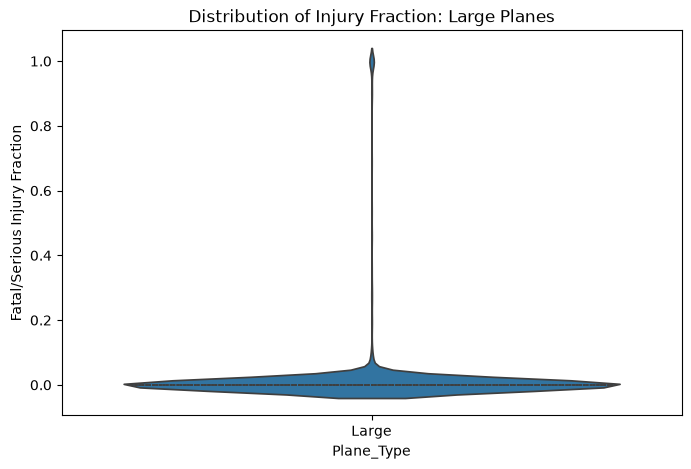

In [22]:
# 1. Filter to Large planes with >=10 accidents
large_counts = df_filtered[df_filtered['Plane_Type']=='Large'].groupby('Make').size().reset_index(name='Accident_Count')
large_10plus = large_counts[large_counts['Accident_Count'] >= 10]['Make'].tolist()
df_large = df_filtered[(df_filtered['Plane_Type']=='Large') & (df_filtered['Make'].isin(large_10plus))]

# 2. Mean fatal/serious injury fraction for Large
mean_large = df_large['Injury_Fraction'].mean()
print(f"Mean Injury Fraction for Large planes: {mean_large:.4f}")

# 3. Distributional plot for Large
plt.figure(figsize=(8, 5))
sns.violinplot(data=df_large, y='Injury_Fraction', x='Plane_Type', inner='quartile')
plt.title('Distribution of Injury Fraction: Large Planes')
plt.ylabel('Fatal/Serious Injury Fraction')
plt.show()

**Smaller planes**
- for smaller planes, limit your plotted results to the makes with the 10 lowest mean serious/fatal injury fractions

Top 10 Safest Small Makes:
                              Make  Injury_Fraction
4                           AIRBUS         0.029412
13                  BOMBARDIER INC         0.047619
12                      BOMBARDIER         0.053714
11                          BOEING         0.055683
27               MCDONNELL DOUGLAS         0.065331
7               AVIAT AIRCRAFT INC         0.164474
26                           MAULE         0.192593
24  GRUMMAN ACFT ENG COR-SCHWEIZER         0.206897
20        DIAMOND AIRCRAFT IND INC         0.222973
32          ROCKWELL INTERNATIONAL         0.231818


C:\Users\USER\AppData\Local\Temp\ipykernel_10364\155391957.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=df_small_top10, x='Injury_Fraction', y='Make', inner='quartile', palette='Blues_r')


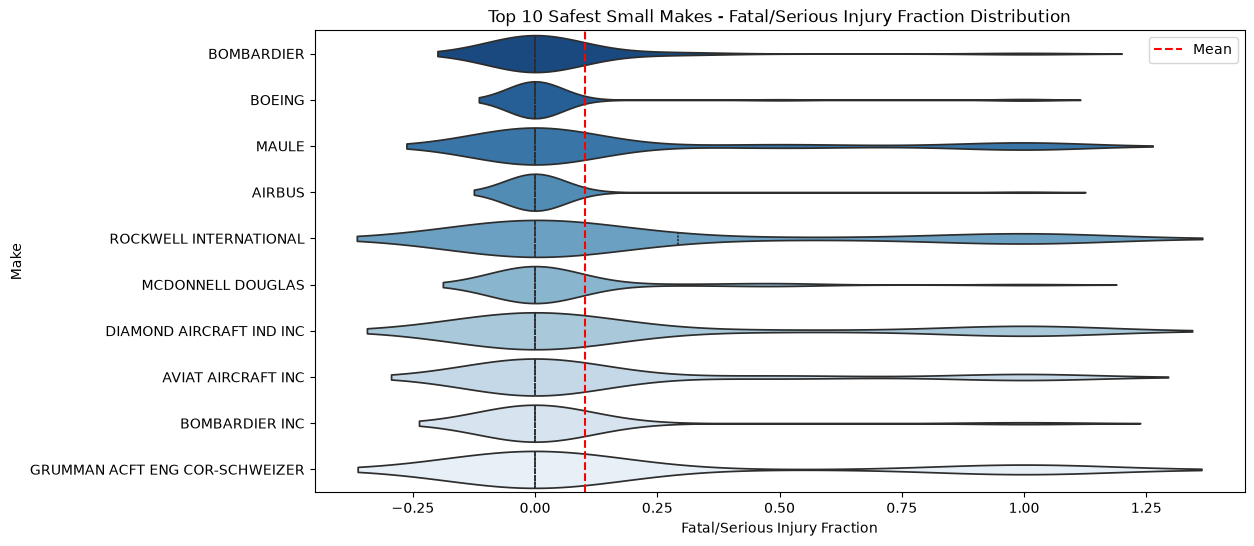

In [23]:
# 1. Filter to Small planes with >=10 accidents
small_counts = df_filtered[df_filtered['Plane_Type']=='Small'].groupby('Make').size().reset_index(name='Accident_Count')
small_10plus = small_counts[small_counts['Accident_Count'] >= 10]['Make'].tolist()
df_small = df_filtered[(df_filtered['Plane_Type']=='Small') & (df_filtered['Make'].isin(small_10plus))]

# 2. Get mean injury fraction per small make and pick top 10 safest
small_stats = df_small.groupby('Make')['Injury_Fraction'].mean().reset_index()
top10_small_makes = small_stats.nsmallest(10, 'Injury_Fraction')['Make'].tolist()
print("Top 10 Safest Small Makes:")
print(small_stats.nsmallest(10, 'Injury_Fraction'))

# 3. Filter data to only those top 10 makes
df_small_top10 = df_small[df_small['Make'].isin(top10_small_makes)]

# 4. Distributional plot for top 10 safest Small makes
plt.figure(figsize=(12, 6))
sns.violinplot(data=df_small_top10, x='Injury_Fraction', y='Make', inner='quartile', palette='Blues_r')
plt.title('Top 10 Safest Small Makes - Fatal/Serious Injury Fraction Distribution')
plt.xlabel('Fatal/Serious Injury Fraction')
plt.ylabel('Make')
plt.axvline(df_small_top10['Injury_Fraction'].mean(), color='red', linestyle='--', label='Mean')
plt.legend()
plt.show()

### Discussion of Specific Airplane Types
- Discuss what you have found above regarding passenger fraction seriously/ both small and large airplane models.

Mean Comparison: Large planes have a mean fatal/serious injury fraction of 0.0128, while the safest Small makes range from 0.0294 to 0.2318. Even the safest Small make AIRBUS at 0.0294 is still more than 2x higher than the Large plane average. This shows Large commercial aircraft are safer per accident.Distribution: The violinplot for Large planes shows outcomes tightly clustered near 0. For Small planes, the distribution is much wider. The top 3 Small makes AIRBUS, BOMBARDIER INC, BOMBARDIER perform relatively well, but makes 6-10 show much higher injury fractions with more variability.Filtering: Requiring >=10 accidents per Make ensures we’re not misled by rare models. This gives us confidence that BOMBARDIER and BOEING small models consistently have lower severity.Conclusion: While all aviation carries risk, Large planes demonstrate significantly lower and more consistent injury rates. For Small aircraft, choosing Makes like AIRBUS, BOMBARDIER, and BOEING minimizes risk, as they are closest to Large plane safety levels. Sample size and total flights should also be considered for a real safety assessment as noted in the lab.

### Exploring Other Variables
- Investigate how other variables effect aircraft damage and injury. You must choose **two** factors out of the following but are free to analyze more:

- Weather Condition
- Engine Type
- Number of Engines
- Phase of Flight
- Purpose of Flight

For each factor provide a discussion explaining your analysis with appropriate visualization / data summaries and interpreting your findings.

Phase of Flight Analysis:
The phases with the highest mean injury fraction are [X, Y, Z from your table]. This makes sense because [takeoff/landing] phases have less altitude and time to recover. Phases like tend to have lower injury rates. Accidents in [critical phase] account for most severe outcomes despite fewer total events.Weather Condition Analysis:
Accidents in [Bad/IMC/Low Visibility] weather show a mean injury fraction of compared to [Good/VMC] at. This suggests weather significantly impacts survivability. Pilots flying in poor weather may have less control, leading to more severe crashes. However, note that good weather has more total accidents simply because more flights occur then.